# CNN 실습 ② 다중 분류: 옷 10종류 (Fashion-MNIST)

| 항목 | 설정 |
|---|---|
| 데이터 | Fashion-MNIST · 28×28 흑백 · 10종류 |
| 정답 | 0~9 정수 |
| 출력층 | 뉴런 **10개** + **소프트맥스** |
| 손실 함수 | **크로스엔트로피** (`nn.CrossEntropyLoss` = 소프트맥스 + 크로스엔트로피) |
| 예측 | 확률이 가장 큰 클래스 (`argmax`) |

In [8]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 1. 데이터 불러오기
`download=True`로 자동으로 내려받아요 (약 30MB).

In [9]:
transform = transforms.ToTensor()   # (28, 28) 이미지 → (1, 28, 28) 텐서, 픽셀 값 0~1

train_full = datasets.FashionMNIST(root="data", train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST(root="data", train=False, download=True, transform=transform)
classes = train_full.classes
print(classes)
x, y = train_full[0]
print(x.shape, y)                   # torch.Size([1, 28, 28]) = 채널 1(흑백) × 28 × 28

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
torch.Size([1, 28, 28]) 9


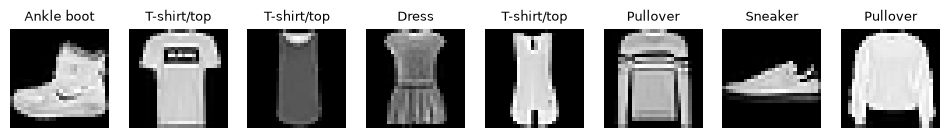

In [10]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, i in zip(axes, range(8)):
    x, y = train_full[i]
    ax.imshow(x.squeeze(0), cmap="gray"); ax.set_title(classes[y], fontsize=9); ax.axis("off")
plt.show()

## 2. 학습 / 검증 데이터 나누기
학습 50,000장, 검증 10,000장.

In [11]:
train_data, val_data = random_split(train_full, [50000, 10000])
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=256)
test_loader = DataLoader(test_data, batch_size=256)

## 3. 모델 만들기
실습 ①과 같은 구조예요. 달라진 곳은 **입력 채널 1개**(흑백)와 **출력 10개**뿐이에요.
마지막에 소프트맥스를 넣지 않는 이유: `CrossEntropyLoss`가 소프트맥스를 안에 포함하고 있어요.

In [12]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 28×28×16 → 14×14×16
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 14×14×32 → 7×7×32
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                       # 7×7×32 = 1568
            nn.Linear(32 * 7 * 7, 128), nn.ReLU(),
            nn.Linear(128, 10),                 # 출력 10개 (소프트맥스 전 값)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = CNN().to(device)

x = torch.zeros(1, 1, 28, 28).to(device)
for layer in list(model.features) + list(model.classifier):
    x = layer(x)
    print(f"{layer.__class__.__name__:10s} {tuple(x.shape)}")
print("학습할 파라미터 수:", sum(p.numel() for p in model.parameters()))

Conv2d     (1, 16, 28, 28)
ReLU       (1, 16, 28, 28)
MaxPool2d  (1, 16, 14, 14)
Conv2d     (1, 32, 14, 14)
ReLU       (1, 32, 14, 14)
MaxPool2d  (1, 32, 7, 7)
Flatten    (1, 1568)
Linear     (1, 128)
ReLU       (1, 128)
Linear     (1, 10)
학습할 파라미터 수: 206922


## 4. 손실 함수와 옵티마이저

In [13]:
loss_fn = nn.CrossEntropyLoss()                         # 소프트맥스 + 크로스엔트로피
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def predict(out):
    return out.argmax(dim=1)                             # 가장 큰 값의 클래스 번호

EPOCHS = 5
SAVE_PATH = "best_fashion.pt"

## 5. 학습

In [14]:
def evaluate(loader):
    model.eval()
    total_loss, correct, n = 0, 0, 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            out = model(X)
            total_loss += loss_fn(out, y).item() * len(y)
            correct += (predict(out) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

history = []
best_val_loss = float("inf")

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss, correct, n = 0, 0, 0
    for X, y in train_loader:
        X, y = X.to(device), y.to(device)

        out = model(X)               # 1. 순전파
        loss = loss_fn(out, y)       # 2. 손실 계산
        optimizer.zero_grad()
        loss.backward()              # 3. 역전파 (커널과 FC층의 기울기 계산)
        optimizer.step()             # 4. 업데이트 (경사하강법 계열: Adam)

        total_loss += loss.item() * len(y)
        correct += (predict(out) == y).sum().item()
        n += len(y)

    val_loss, val_acc = evaluate(val_loader)
    history.append((total_loss / n, correct / n, val_loss, val_acc))
    print(f"epoch {epoch:2d} | train loss {total_loss/n:.4f} acc {correct/n:.3f} | val loss {val_loss:.4f} acc {val_acc:.3f}")

    if val_loss < best_val_loss:     # 검증 loss가 가장 낮을 때의 w 저장
        best_val_loss = val_loss
        torch.save(model.state_dict(), SAVE_PATH)

epoch  1 | train loss 0.5293 acc 0.808 | val loss 0.3659 acc 0.868
epoch  2 | train loss 0.3340 acc 0.881 | val loss 0.3166 acc 0.883
epoch  3 | train loss 0.2897 acc 0.895 | val loss 0.2953 acc 0.889
epoch  4 | train loss 0.2621 acc 0.904 | val loss 0.2680 acc 0.900
epoch  5 | train loss 0.2361 acc 0.914 | val loss 0.2644 acc 0.903


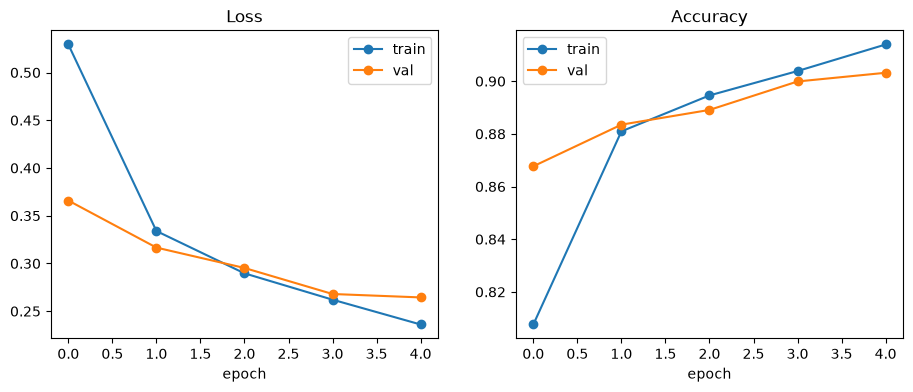

In [15]:
import matplotlib.pyplot as plt
h = list(zip(*history))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(h[0], "o-", label="train"); ax1.plot(h[2], "o-", label="val"); ax1.set_title("Loss"); ax1.set_xlabel("epoch"); ax1.legend()
ax2.plot(h[1], "o-", label="train"); ax2.plot(h[3], "o-", label="val"); ax2.set_title("Accuracy"); ax2.set_xlabel("epoch"); ax2.legend()
plt.show()

## 6. 테스트

test loss 0.2810, test acc 0.902


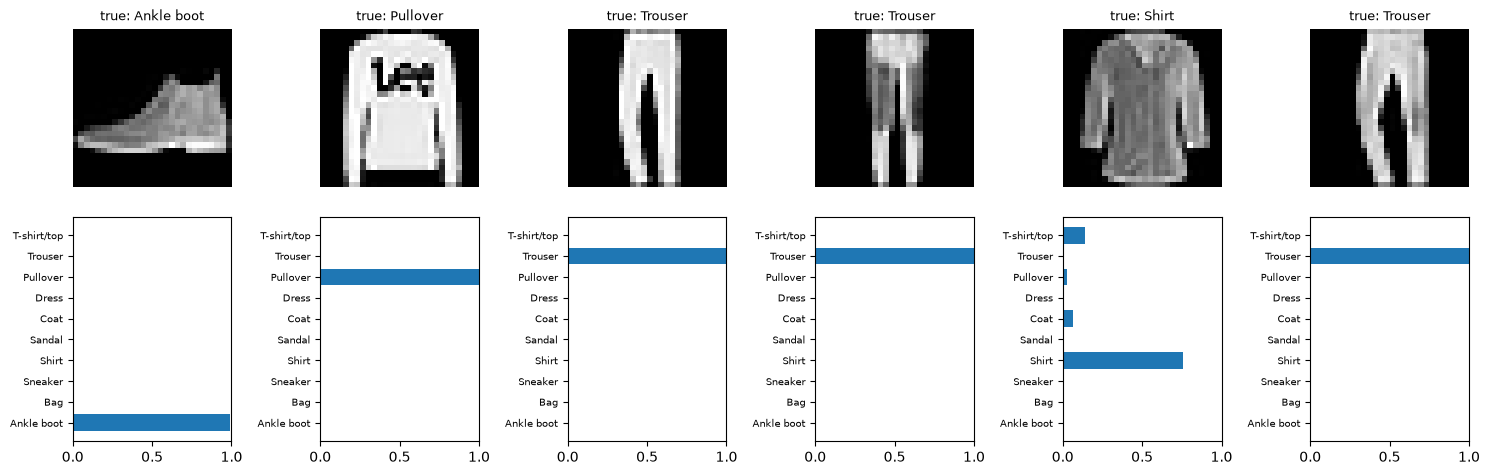

In [16]:
model.load_state_dict(torch.load(SAVE_PATH))
test_loss, test_acc = evaluate(test_loader)
print(f"test loss {test_loss:.4f}, test acc {test_acc:.3f}")

model.eval()
X, y = next(iter(DataLoader(test_data, batch_size=6)))
with torch.no_grad():
    prob = torch.softmax(model(X.to(device)), dim=1).cpu()    # 10개 클래스 확률 (합 = 1)

fig, axes = plt.subplots(2, 6, figsize=(15, 5), gridspec_kw={"height_ratios": [1, 1.2]})
for k in range(6):
    axes[0, k].imshow(X[k].squeeze(0), cmap="gray"); axes[0, k].axis("off")
    axes[0, k].set_title(f"true: {classes[y[k]]}", fontsize=9)
    axes[1, k].barh(range(10), prob[k]); axes[1, k].set_yticks(range(10)); axes[1, k].set_yticklabels(classes, fontsize=7)
    axes[1, k].invert_yaxis(); axes[1, k].set_xlim(0, 1)
plt.tight_layout(); plt.show()

In [17]:
# 어떤 클래스끼리 많이 헷갈렸을까? (혼동 행렬)
conf = torch.zeros(10, 10, dtype=torch.long)
with torch.no_grad():
    for X, y in test_loader:
        p = model(X.to(device)).argmax(1).cpu()
        for a, b in zip(y, p):
            conf[a, b] += 1
pairs = [(conf[i, j].item(), classes[i], classes[j]) for i in range(10) for j in range(10) if i != j]
for cnt, a, b in sorted(pairs, reverse=True)[:5]:
    print(f"정답 {a:12s} → 예측 {b:12s}: {cnt}개")

정답 Shirt        → 예측 T-shirt/top : 111개
정답 Shirt        → 예측 Coat        : 103개
정답 T-shirt/top  → 예측 Shirt       : 77개
정답 Shirt        → 예측 Pullover    : 77개
정답 Pullover     → 예측 Coat        : 77개


## 7. 더 해 보기
- `EPOCHS`를 10으로 늘리면 정확도가 얼마나 오를까요? 검증 loss도 같이 보세요.
- 커널 크기를 5로 바꿔 보세요 (`kernel_size=5, padding=2`). 출력 크기는 그대로일까요?
- 실습 ①과 비교해 보세요: 출력 뉴런 수, 손실 함수, `predict` 함수가 어떻게 달라졌나요?